In [ ]:
import os

# Change the backend before the first PyRITE import; restart to change it.
os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

_ = pyrite.fetch_tables()  # Install missing pinned reference tables once.
tables_ready = True

# Electron trajectories: where X-rays come from

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/00-electron-trajectories.py)

Before calculating a spectrum, PyRITE follows sampled _electron histories_
through the target. Each straight flight, or _segment_, has a position,
direction, path length and changing kinetic energy. Elastic scattering
changes the next flight's direction, while the material's _stopping power_
reduces the energy as the electron moves.

Here **16,384 sampled 30 keV electrons** enter a **4 µm HOPG slab** normally.
We use a point beam, an infinite lateral slab and the lightweight analytic
screened-Rutherford elastic model (`"sr"`) to keep the example CPU-friendly.
Production calculations may instead use the tabulated ELSEPA model.

This is the _transport_ part of a simulation, so no spectral calculations
are conducted yet. The fixed `seed = 1` makes runs repeatable, but only
for this particular combination of backend and transport core.

In [ ]:
from pyrite.transport import simulate_trajectories
from pyrite.units import ureg

histories = 16_384
seed = 1
thickness_nm = (4 * ureg.um).to("nm").magnitude
assert tables_ready  # Finish reference-table setup before transport.
transport_result = simulate_trajectories(
    E0_keV=(30 * ureg.keV).magnitude,
    Ne=histories,
    thickness_ang=(thickness_nm * ureg.nm).to("angstrom").magnitude,
    composition=[("C", 0.11363677327755675)],  # HOPG carbon atoms / Å³
    elastic_model="sr",
    transport_core="lockstep",
    energy_model="midpoint",
    E_cut_keV=(5 * ureg.keV).magnitude,
    max_steps=20_000,
    seed=seed,
)

## Follow the electrons

`simulate_trajectories()` returns NumPy arrays, **one entry per material
segment**—not one entry per electron. Instead, each entry has an `electron_id`
field which tags the electron it is assoicated with. The entry `r_mid` is
the midpoint in **Å**, `v_hat` the direction unit vector, and `L_ang` the
segment length in **Å**. Thus the two endpoints are

$$\mathbf r_\pm = \mathbf r_{\rm mid} \pm \frac{L}{2}\hat{\mathbf v}.$$

`E_start_keV` and `E_end_keV` describe the continuously slowing electron.
We color each segment by its mean kinetic energy, not by photon energy.
The plot shows **32 of the 16,384 histories** so individual turns remain visible.
The entrance is at depth 0; the exit face is at 4,000 nm.

In [ ]:
rows = transport_result
midpoint = np.asarray(rows["r_mid"])
direction = np.asarray(rows["v_hat"])
length = np.asarray(rows["L_ang"])
electron_ids = np.asarray(rows["electron_id"])
energy_start_keV = np.asarray(rows["E_start_keV"])
energy_end_keV = np.asarray(rows["E_end_keV"])
event_codes = np.asarray(rows["event_kind"])

# Midpoint rows may arrive in step-major order: do not assume the last
# array entry belonging to an electron is its final transport segment.
order = np.lexsort((rows["substep_id"], rows["flight_id"], electron_ids))
is_terminal = np.r_[np.diff(electron_ids[order]) != 0, True]
last_rows = order[is_terminal]
assert len(last_rows) == histories

starts_nm = (midpoint - length[:, None] * direction / 2) / 10.0
ends_nm = (midpoint + length[:, None] * direction / 2) / 10.0
representative_keV = 0.5 * (energy_start_keV + energy_end_keV)
displayed_rows = electron_ids < 32

# Midpoint is a continuous-energy scoring point, not the position of an
# elastic event: event_kind identifies the event at the *far endpoint*.

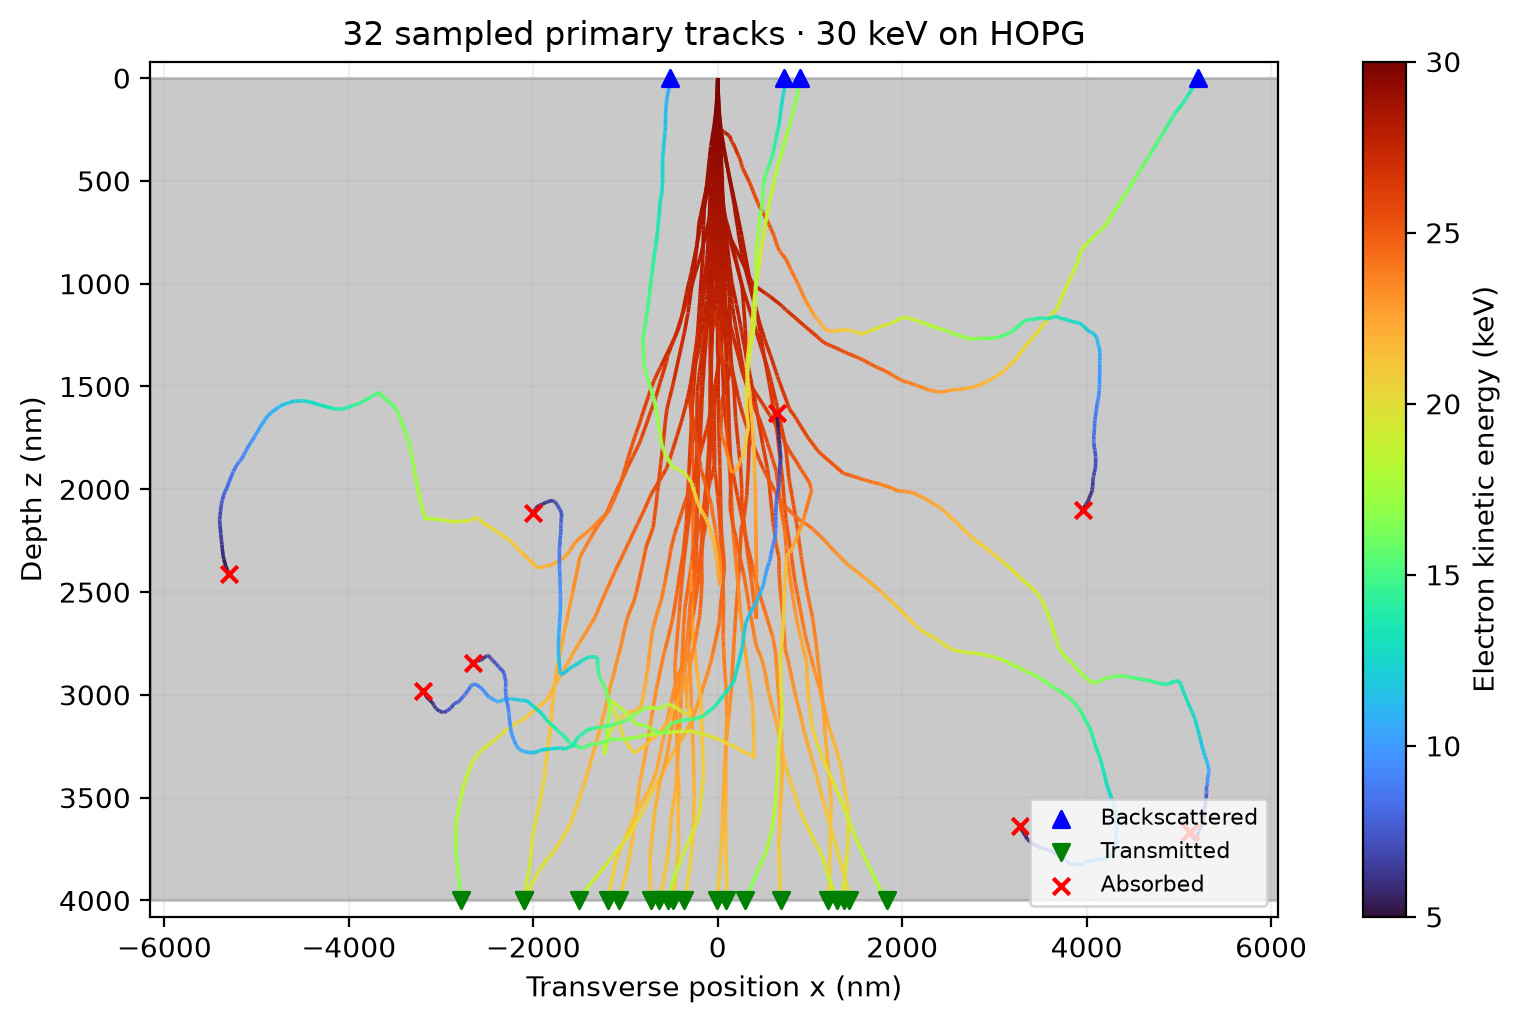

In [ ]:
from matplotlib.collections import LineCollection

# Two-dimensional projection of the true three-dimensional segments.
lines = np.stack((starts_nm[displayed_rows][:, [0, 2]], ends_nm[displayed_rows][:, [0, 2]]), axis=1)
fig_tracks, ax_tracks = plt.subplots(figsize=(7.5, 5), layout="constrained")
ax_tracks.axhspan(0, thickness_nm, color="0.4", alpha=0.35, zorder=0)
tracks = LineCollection(lines, cmap="turbo", linewidths=1.3)
tracks.set_array(representative_keV[displayed_rows])
tracks.set_clim(5, 30)
ax_tracks.add_collection(tracks)

# Mark visible terminal track endpoints, using row-end event codes:
# 4 = exit through entrance (backscatter), 5 = exit through back face.
fate_legend = (
    (4, "^", "Backscattered", "b"),
    (5, "v", "Transmitted", "g"),
    (7, "x", "Absorbed", "r"),
)
for code, symbol, label, color in fate_legend:
    selected = last_rows[
        (last_rows < len(displayed_rows))
        & displayed_rows[last_rows]
        & (event_codes[last_rows] == code)
    ]
    if selected.size:
        ax_tracks.scatter(
            ends_nm[selected, 0],
            ends_nm[selected, 2],
            marker=symbol,
            s=35,
            label=label,
            zorder=3,
            color=color,
        )
extent = np.concatenate((starts_nm[displayed_rows, 0], ends_nm[displayed_rows, 0]))
margin = max(80.0, 0.07 * np.ptp(extent))
ax_tracks.set(
    xlim=(extent.min() - margin, extent.max() + margin),
    ylim=(thickness_nm + 80.0, -80.0),
    xlabel="Transverse position x (nm)",
    ylabel="Depth z (nm)",
    title="32 sampled primary tracks · 30 keV on HOPG",
)
ax_tracks.grid(alpha=0.2)
if ax_tracks.get_legend_handles_labels()[0]:
    ax_tracks.legend(loc="lower right", fontsize=8)
fig_tracks.colorbar(tracks, ax=ax_tracks, label="Electron kinetic energy (keV)")
fig_tracks  # noqa: B018 - display the figure in marimo

## Depth, energy and exit outcomes

To avoid confusing the **number of saved segments** with the electron
population, we use the final `event_kind` of each primary history for its
fate. `EXIT_TOP=4` means backscattered, `EXIT_BOTTOM=5` transmitted,
`EXIT_SIDE=6` escaped laterally, and `CUTOFF=7` stopped at the 5 keV
tracking threshold. The exit-energy histogram includes only escaped
primaries; cutoff-stopped histories are counted in the fate plot instead.

The depth profile attributes the continuous loss
`E_start_keV - E_end_keV` across the depth span of each straight segment,
then divides by the number of **incident sampled electrons** and bin
width. This is a **continuous energy-loss profile**, _not_ a PXR,
bremsstrahlung, photon-emission or absorbed-dose profile. An electron can
traverse the same depth bin more than once after scattering.

In [ ]:
depth_edges_nm = np.linspace(0, thickness_nm, 41)
low = np.minimum(starts_nm[:, 2], ends_nm[:, 2])[:, None]
high = np.maximum(starts_nm[:, 2], ends_nm[:, 2])[:, None]
dz = high - low
overlap = np.maximum(0, np.minimum(high, depth_edges_nm[1:]) - np.maximum(low, depth_edges_nm[:-1]))
shares = np.divide(overlap, dz, out=np.zeros_like(overlap), where=dz > 1e-12)
# Zero-depth-span (nearly transverse) rows deposit in their midpoint bin.
flat = dz[:, 0] <= 1e-12
if np.any(flat):
    index = np.searchsorted(depth_edges_nm, starts_nm[flat, 2], side="right") - 1
    valid = (index >= 0) & (index < len(depth_edges_nm) - 1)
    shares[np.flatnonzero(flat)[valid], index[valid]] = 1.0
continuous_loss_keV = np.maximum(0, energy_start_keV - energy_end_keV)
depth_loss_per_electron_nm = (
    np.sum(shares * continuous_loss_keV[:, None], axis=0) / histories / np.diff(depth_edges_nm)
)

fates = {
    "Backscatter": int(transport_result["n_backscattered"]),
    "Transmission": int(transport_result["n_transmitted"]),
    "Side exit": int(transport_result["n_side_exited"]),
    "Cutoff stop": int(transport_result["n_cutoff_stopped"]),
}
assert sum(fates.values()) + int(transport_result.get("n_missed", 0)) == histories
assert np.count_nonzero(event_codes[last_rows] == 4) == fates["Backscatter"]
assert np.count_nonzero(event_codes[last_rows] == 5) == fates["Transmission"]
escaped_top_keV = energy_end_keV[last_rows[event_codes[last_rows] == 4]]
escaped_bottom_keV = energy_end_keV[last_rows[event_codes[last_rows] == 5]]
# A cross-check of the unweighted history denominator (not the row count).
assert len(np.unique(electron_ids)) == histories

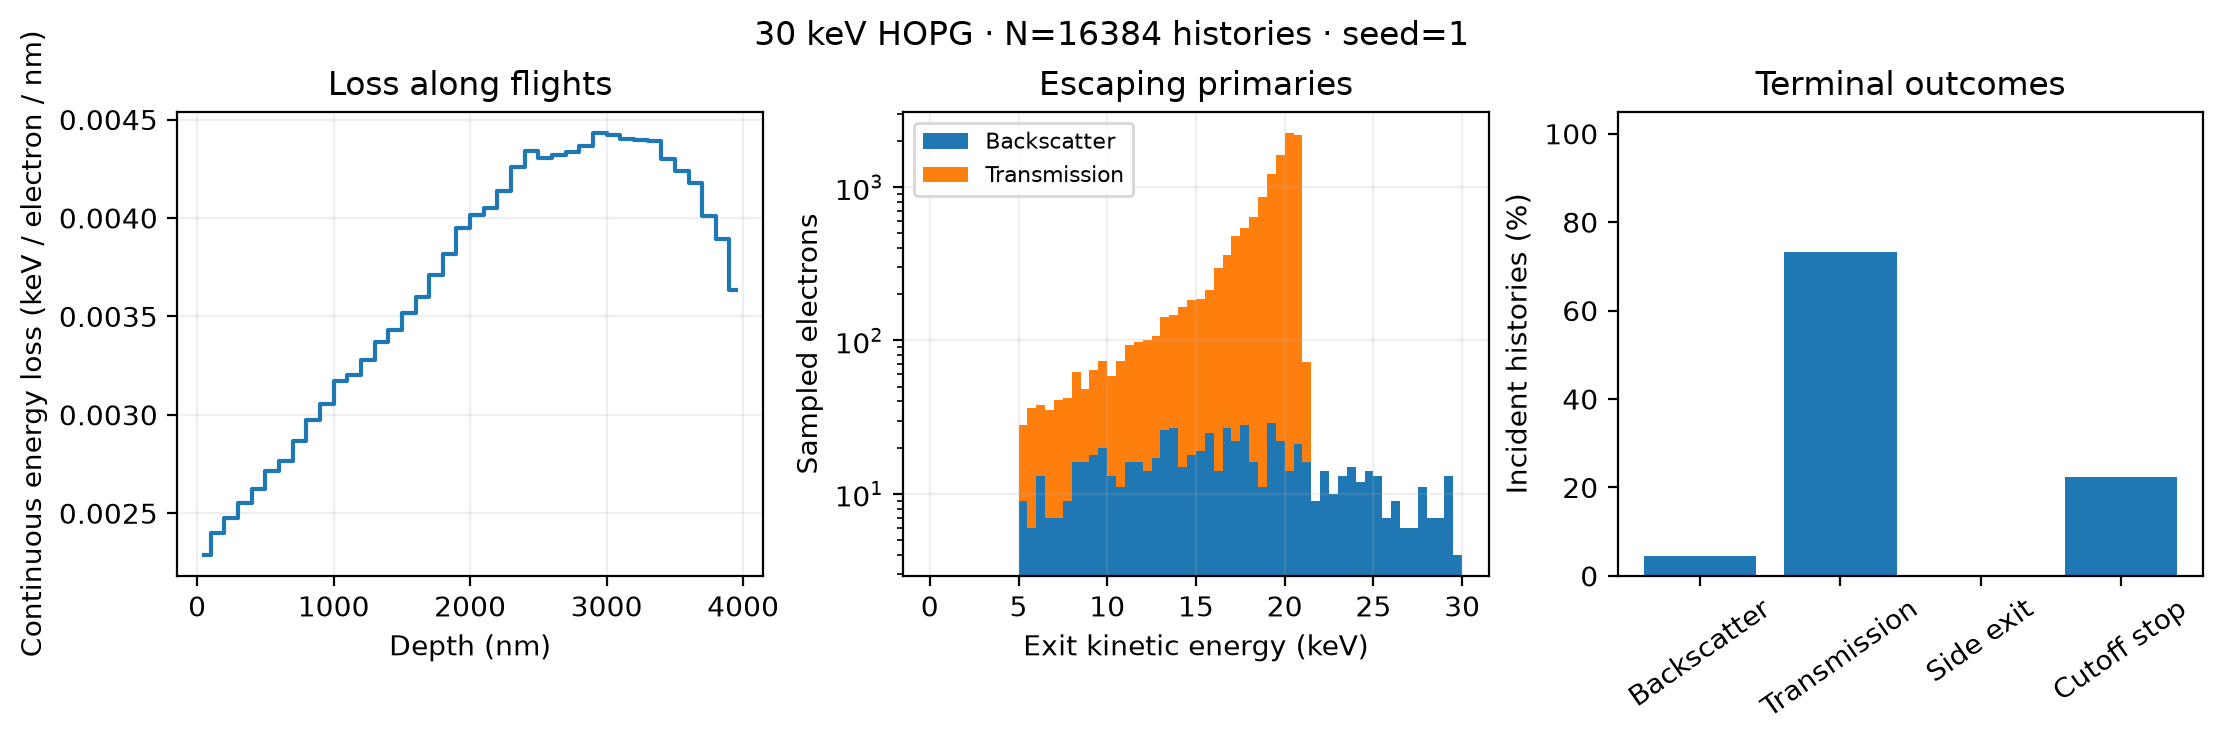

In [ ]:
fig_summary, axes = plt.subplots(1, 3, figsize=(11, 3.6), layout="constrained")
centers = 0.5 * (depth_edges_nm[1:] + depth_edges_nm[:-1])
axes[0].step(centers, depth_loss_per_electron_nm, where="mid")
axes[0].set(
    xlabel="Depth (nm)",
    ylabel="Continuous energy loss (keV / electron / nm)",
    title="Loss along flights",
)
axes[0].grid(alpha=0.2)

bins = np.linspace(0, 30, 61)
axes[1].hist(
    [escaped_top_keV, escaped_bottom_keV],
    bins=bins,
    label=["Backscatter", "Transmission"],
    stacked=True,
)
axes[1].set(
    xlabel="Exit kinetic energy (keV)",
    ylabel="Sampled electrons",
    title="Escaping primaries",
    yscale="log",
)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.2)

labels = list(fates)
percentages = [100.0 * count / histories for count in fates.values()]
axes[2].bar(range(len(labels)), percentages)
axes[2].set(
    xticks=range(len(labels)),
    xticklabels=labels,
    ylabel="Incident histories (%)",
    ylim=(0, 105),
    title="Terminal outcomes",
)
axes[2].tick_params(axis="x", labelrotation=35)
fig_summary.suptitle(f"30 keV HOPG · N={histories} histories · seed={seed}")
fig_summary  # noqa: B018 - display the figure in marimo

## How the tracks become X-ray predictions

**Elastic collisions** kink the track. **Continuous inelastic losses**
reduce its kinetic energy; this simplified call does not explicitly
transport secondary electrons or sample individual hard bremsstrahlung
photons. With `energy_model="midpoint"`, the row-end `event_kind` marks
the interaction or boundary _after_ the straight segment.

Downstream radiation calculations integrate contributions _along individual
segments_. The bremsstrahlung continuum is produced by electron–atom
interactions; PXR/CBS requires the electron's electromagnetic field to
scatter from the periodic crystal. PXR/CBS contributions are phase- and
observation-direction-dependent, so a high energy-loss bin is **not**
necessarily a strong X-ray-emission bin. This public transport call does
not return emission-weighted depth; we deliberately do not invent one.

In a **thin** target, electrons usually have less opportunity to scatter
and lose energy before leaving, preserving the incident direction and
energy relevant to a narrow PXR resonance. More material can increase
the total radiation opportunity, but also increases scattering,
dephasing and photon attenuation; thinner is **not always brighter**.
Change `thickness_nm` to 100, rerun, and compare the outcomes. More
histories are needed for precise backscatter probabilities.

Finally, **16,384 numerical histories are not 16,384 electrons in a bunch**.
A physical beam usually contains many more electrons; radiation yields per
incident electron are subsequently scaled using the physical beam
current.

Next: [Your first X-ray spectrum](01-first-spectrum.ipynb),
[How PyRITE works](../../physics/how-pyrite-works.md),
[electron transport physics](../../physics/beam-transport/electron-transport.md),
[transport row contract](../../physics/beam-transport/transport-outputs.md), and
[transport validation ledger](../../validation/ledger-transport-background.md).

## Continue learning

Continue to [Your first X-ray spectrum](01-first-spectrum.ipynb). Compare the
[transport physics](../../physics/beam-transport/electron-transport.md),
[transport outputs](../../physics/beam-transport/transport-outputs.md),
[How PyRITE works](../../physics/how-pyrite-works.md), and
[transport validation ledger](../../validation/ledger-transport-background.md).

{download}`Download canonical Marimo notebook <../00-electron-trajectories.py>`